
# Retail Sales Analysis Using Python

## 1. Project Overview

This project analyses retail transaction data to identify sales trends, customer purchasing patterns, and product performance.

## 2. Project Objectives

- Analyse overall retail sales performance.
- Identify top-performing products.
- Examine monthly revenue trends.
- Understand customer purchasing behaviour.
- Compare sales performance across countries.
- Generate actionable business insights.

## 3. Tools and Technologies

- Python
- Google Colab
- Pandas
- NumPy
- Matplotlib
- Seaborn


In [44]:

# Import the libraries required for our project

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display a confirmation message

print("Retail Sales Analysis environment is ready!")

# Check the Pandas version

print("Pandas version:", pd.__version__)


Retail Sales Analysis environment is ready!
Pandas version: 2.2.3


In [45]:
#Load the excel data set
df = pd.read_excel("Online Retail.xlsx")
#Display first 5 rows
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [46]:
#check the number of rows and columns
df.shape

(541909, 8)

In [47]:
#display column names
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')

# **Understand the structure using df.info()**

What does this do?

It provides a summary of your dataset, including:
- Column names
- Number of non-null records in each column
- Data type of each column
- Memory usage





*Note: Excel date columns sometimes load as objects or datetime values depending on how the data is stored. We'll check this rather than assume.*

**Why is df.info() important?**

Imagine your dataset has 500,000 rows, but the CustomerID column only has 400,000 non-null values.

That means some transactions do not have a customer ID. This is an important discovery before analysing customer behaviour.

df.info() helps us spot these issues early.

In [48]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


## **Calculate descriptive statistics using df.describe()**

This calculates statistical summaries for numerical columns.


In [49]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


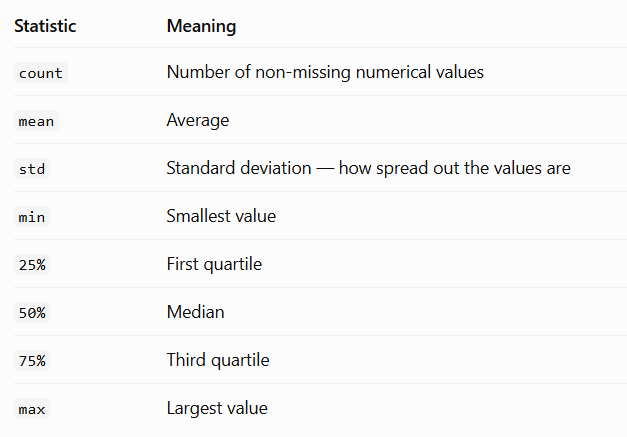

# Include categorical columns in the statistical summary
By default, df.describe() focuses on numerical columns.

But our dataset also contains text columns, such as:
- Description
- Country
- InvoiceNo
- StockCode

Let's inspect those as well.

This provides summaries for numerical and non-numerical columns.

Some useful statistics you may see:
- *unique* – number of distinct values
- *top* – most frequently occurring value
- *freq* – frequency of the most common value

For example, if Country shows 38 unique values, that tells us how many distinct countries are represented in the dataset.

In [50]:
df.describe(include="all")

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
count,541909.0,541909,540455,541909.000000,541909,541909.000000,406829.000000,541909
unique,25900.0,4070,4223,NaN,NaN,NaN,NaN,38
top,573585.0,85123A,WHITE HANGING HEART T-LIGHT HOLDER,NaN,NaN,NaN,NaN,United Kingdom
freq,1114.0,2313,2369,NaN,NaN,NaN,NaN,495478
mean,NaN,NaN,NaN,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570,NaN
min,NaN,NaN,NaN,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000,NaN
25%,NaN,NaN,NaN,1.000000,2011-03-28 11:34:00,1.250000,13953.000000,NaN
50%,NaN,NaN,NaN,3.000000,2011-07-19 17:17:00,2.080000,15152.000000,NaN
75%,NaN,NaN,NaN,10.000000,2011-10-19 11:27:00,4.130000,16791.000000,NaN
max,NaN,NaN,NaN,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000,NaN



## Dataset Overview

### Dataset Structure
- Number of rows: 541909
- Number of columns: 8


### Data Types
- Numerical columns: 3
- Text/categorical columns: 4
- Date columns: 1

## Initial Observations
### Preliminary Dataset Findings

- The dataset contains 541,909 transaction line records and 8 columns.
- The transactions span from December 2010 to December 2011.
- The dataset represents 38 countries, with the United Kingdom accounting for approximately 91.4% of transaction records.
- The median quantity per transaction line is 3 items, while the mean is approximately 9.55, suggesting the presence of unusually large quantities.
- The median unit price is £2.08, while the mean is £4.61, suggesting a right-skewed distribution of prices.


### Initial Data Quality Concerns
- Negative quantities and negative unit prices indicate records that require further investigation, potentially related to returns, cancellations, or adjustments.
- CustomerID contains missing values, which may affect customer-level analysis.
- Some product descriptions are missing and will require data quality investigation.


# Step 4: Investigate missing data

In [51]:
# Count missing values in every column

df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


Understanding the code

**df.isnull()** -	*Checks every cell and returns True if the value is missing*

**.sum()** - *Counts the True values in each column*

Python treats True as 1 and False as 0 when summing, which is why this gives us the number of missing records per column.

In [52]:
# Calculate missing values as a percentage of total records

(df.isnull().sum() / len(df)) * 100

,0
InvoiceNo,0.000000
StockCode,0.000000
Description,0.268311
Quantity,0.000000
InvoiceDate,0.000000
UnitPrice,0.000000
CustomerID,24.926694
Country,0.000000


In [53]:
# Create a summary of missing data

missing_summary = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df)) * 100
})


# Display only columns that have missing values

missing_summary = missing_summary[missing_summary["Missing Values"] > 0]

missing_summary

,Missing Values,Missing Percentage
Description,1454,0.268311
CustomerID,135080,24.926694


## Missing Data - Analysis

The dataset contains missing values in two columns:

- **CustomerID:** 135,080 missing values (24.93%).
- **Description:** 1,454 missing values (0.27%).

CustomerID has a substantial amount of missing data, which may limit customer-level analyses such as segmentation, retention and purchasing behaviour.

Missing product descriptions affect a relatively small proportion of the dataset. The StockCode column may help identify products with missing descriptions.

### Data Cleaning Decision

Missing records will not be removed immediately. Their impact will be evaluated based on the objectives of each analysis. The original dataset will be preserved, and a separate cleaned dataset will be created during the data-cleaning phase.

# Detecting duplicate records

## What is a duplicate record?

A duplicate record is a row that repeats information already present in another row.

However, there is an important distinction:

Two records that look similar are not necessarily duplicates. We need to confirm whether the entire row is duplicated and consider the business context before removing it.

In [54]:
# Count the number of duplicate rows in the dataset

df.duplicated().sum()

np.int64(5268)

In [55]:
# Display the duplicate records

duplicates = df[df.duplicated()]

duplicates.head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom
587,536412,22273,FELTCRAFT DOLL MOLLY,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom
589,536412,22749,FELTCRAFT PRINCESS CHARLOTTE DOLL,1,2010-12-01 11:49:00,3.75,17920.0,United Kingdom
594,536412,22141,CHRISTMAS CRAFT TREE TOP ANGEL,1,2010-12-01 11:49:00,2.10,17920.0,United Kingdom
598,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920.0,United Kingdom
600,536412,22569,FELTCRAFT CUSHION BUTTERFLY,2,2010-12-01 11:49:00,3.75,17920.0,United Kingdom


In [56]:
# Check the dimensions of the duplicate dataset

duplicates.shape

(5268, 8)

In [57]:
# Calculate duplicate percentage
duplicate_count = df.duplicated().sum()
duplicate_percentage = (duplicate_count /len(df)) *100

print("Duplicate records:", duplicate_count)
print("Duplicate percentage:", round(duplicate_percentage, 2), "%")

Duplicate records: 5268
Duplicate percentage: 0.97 %


In [58]:
duplicates["InvoiceNo"].value_counts().head(10)
# Check duplicate invoice numbers

,count
InvoiceNo,
555524,34
547651,31
579458,28
574481,27
572103,27
577482,26
537781,25
552285,24
569897,21


In [59]:
# Get the invoice number of the first duplicate row

sample_invoice = duplicates.iloc[0]["InvoiceNo"]

# Display all records belonging to that invoice

df[df["InvoiceNo"] == sample_invoice]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
483,536409,90199C,5 STRAND GLASS NECKLACE CRYSTAL,3,2010-12-01 11:45:00,6.35,17908.0,United Kingdom
484,536409,21479,WHITE SKULL HOT WATER BOTTLE,1,2010-12-01 11:45:00,3.75,17908.0,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
486,536409,22785,SQUARECUSHION COVER PINK UNION FLAG,1,2010-12-01 11:45:00,6.75,17908.0,United Kingdom
487,536409,22975,SPACEBOY CHILDRENS EGG CUP,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
488,536409,22972,CHILDREN'S SPACEBOY MUG,1,2010-12-01 11:45:00,1.65,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
490,536409,22568,FELTCRAFT CUSHION OWL,1,2010-12-01 11:45:00,3.75,17908.0,United Kingdom
491,536409,85116,BLACK CANDELABRA T-LIGHT HOLDER,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
492,536409,22664,TOY TIDY DOLLY GIRL DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom


In [60]:
# Display the first few duplicate rows alongside their originals

df[df.duplicated(keep=False)].sort_values(
    by=["InvoiceNo", "StockCode"]
).head(20)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
565,536412,21448,12 DAISY PEGS IN WOOD BOX,2,2010-12-01 11:49:00,1.65,17920.0,United Kingdom
578,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920.0,United Kingdom


An invoice can contain multiple different products. These are legitimate transaction lines and must be retained.



Found rows repeated exactly across all eight columns. These are exact duplicate records that we can remove from our working dataset.

In [61]:
# Create a copy of the original dataset
df_clean = df.copy()

print("Original dataset:", df.shape)
print("Working dataset:", df_clean.shape)

Original dataset: (541909, 8)
Working dataset: (541909, 8)


# Removing exact duplicate records

In [62]:
# Remove exact duplicate records

df_clean = df_clean.drop_duplicates()

print("Original records:", len(df))
print("Records after removing duplicates:", len(df_clean))
print("Records removed:", len(df) - len(df_clean))

Original records: 541909
Records after removing duplicates: 536641
Records removed: 5268




The initial dataset contained 5,268 exact duplicate records, representing approximately 0.97% of the original dataset.

The duplicate records were reviewed and confirmed to contain repeated entries across all eight columns.

Multiple records sharing the same InvoiceNo were retained because individual invoices can contain multiple legitimate product lines.

### Cleaning Action

- Created a separate working copy of the original dataset.
- Removed exact duplicate rows using Pandas drop_duplicates().
- Preserved the original dataset for reference.
- Verified that no exact duplicate records remained.

### Results

- Original records: 541,909
- Duplicate records removed: 5,268
- Records after cleaning: 536,641
- Remaining exact duplicates: 0

# Investigate negative values and cancelled transactions

## Understand cancelled transactions
In the Online Retail dataset, some invoice numbers begin with the letter C.

 These generally indicate cancelled transactions.

We should investigate them because:
- Cancelled transactions should not be treated as ordinary completed sales.
- Negative quantities may represent returned or cancelled items.
- We need to distinguish actual sales from returns before calculating revenue.

In [63]:
# Identify invoices that begin with the letter C
cancelled_invoices = df_clean[
    df_clean["InvoiceNo"].astype(str).str.startswith("C")
]

# Display the first five cancelled invoice records
cancelled_invoices.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


In [64]:
# Count the number of cancelled invoice records
print("Cancelled invoice records:", len(cancelled_invoices))

# Count unique cancelled invoice numbers
print("Unique cancelled invoices:", cancelled_invoices["InvoiceNo"].nunique())

Cancelled invoice records: 9251
Unique cancelled invoices: 3836


This means:
- There are 9,251 product-line records associated with cancelled invoices.
- Those records belong to 3,836 distinct cancelled invoices.
- A single cancelled invoice can contain multiple products.

## Investigate all negative quantities

In [65]:
# Identify records with negative quantities
negative_quantity = df_clean[df_clean["Quantity"] < 0]

# Count records with negative quantities
print("Records with negative quantities:", len(negative_quantity))

# Display the first 10 records
negative_quantity.head(10)

Records with negative quantities: 10587


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom


### Why are we doing this?

We already know that cancelled invoices contain negative quantities. But we don't yet know whether negative quantities also occur in invoices that don't begin with C.

That distinction matters because we shouldn't automatically classify every negative quantity as a cancellation.

In [66]:
# Count negative quantity records in cancelled invoices
print(
    "Negative quantities in cancelled invoices:",
    len(negative_quantity[
        negative_quantity["InvoiceNo"].astype(str).str.startswith("C")
    ])
)

# Count negative quantity records in other invoices
print(
    "Negative quantities in non-cancelled invoices:",
    len(negative_quantity[
        ~negative_quantity["InvoiceNo"].astype(str).str.startswith("C")
    ])
)

Negative quantities in cancelled invoices: 9251
Negative quantities in non-cancelled invoices: 1336


In [67]:
# Filter negative quantities from non-cancelled invoices
other_negative_records = negative_quantity[
    ~negative_quantity["InvoiceNo"].astype(str).str.startswith("C")
]

# Display the first 15 records
other_negative_records.head(15)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom
4347,536764,84952C,NaN,-38,2010-12-02 14:42:00,0.0,NaN,United Kingdom
7188,536996,22712,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7189,536997,22028,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7190,536998,85067,NaN,-6,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7192,537000,21414,NaN,-22,2010-12-03 15:32:00,0.0,NaN,United Kingdom
7193,537001,21653,NaN,-6,2010-12-03 15:33:00,0.0,NaN,United Kingdom
7195,537003,85126,NaN,-2,2010-12-03 15:33:00,0.0,NaN,United Kingdom
7196,537004,21814,NaN,-30,2010-12-03 15:34:00,0.0,NaN,United Kingdom
7197,537005,21692,NaN,-70,2010-12-03 15:35:00,0.0,NaN,United Kingdom


In [68]:
# Check the UnitPrice values
print("UnitPrice distribution:")
print(other_negative_records["UnitPrice"].value_counts())

# Check missing values in these records
print("\nMissing values:")
print(other_negative_records.isnull().sum())

UnitPrice distribution:
UnitPrice
0.0    1336
Name: count, dtype: int64

Missing values:
InvoiceNo         0
StockCode         0
Description     862
Quantity          0
InvoiceDate       0
UnitPrice         0
CustomerID     1336
Country           0
dtype: int64


What are we trying to establish?

We want to know whether the patterns in the first 15 records apply to all 1,336 records.

Specifically:
- Are all 1,336 records priced at zero?
- Are all product descriptions missing?
- Are all customer IDs missing?
If these patterns are consistent, we can document them as a distinct category of unusual transactions for further investigation.

### Finding: Negative Quantities in Non-Cancelled Invoices

- Identified 1,336 records with negative quantities and invoice numbers not beginning with C.
- All 1,336 records have a UnitPrice of 0.0.
- All 1,336 records have missing CustomerID values.
- 862 records have missing product descriptions.
- These records are classified as unusual transactions requiring further investigation.
- They will be excluded from ordinary sales calculations if they are confirmed to have no sales value, but retained in the original dataset for reference.

# Next investigation: Negative UnitPrice values

In [69]:
# Identify records with negative unit prices
negative_prices = df_clean[df_clean["UnitPrice"] < 0]

# Count records with negative unit prices
print("Records with negative UnitPrice:", len(negative_prices))

# Display the first 10 records
negative_prices.head(10)

Records with negative UnitPrice: 2


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


### Finding: Negative Unit Prices

- Identified 2 records with negative UnitPrice values.
- Both records have the description "Adjust bad debt".
- Both have a UnitPrice of -11,062.06.
- Both have missing CustomerID values.
- These appear to be accounting adjustments rather than ordinary product sales.
- They will be excluded from product sales calculations but retained in the original dataset for reference.

# Identify valid sales transactions

We've investigated three unusual transaction categories:
1. Cancelled invoices: 9,251 records.
2. Negative quantities in non-cancelled invoices: 1,336 records.
3. Negative unit prices: 2 records.

Now let's see how many records remain when we consider only transactions with positive quantities and positive prices.

In [70]:
# Identify records with positive quantities and positive prices
valid_sales = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0)
]

# Compare the original cleaned dataset with valid sales
print("Total cleaned records:", len(df_clean))
print("Valid sales records:", len(valid_sales))
print("Records excluded:", len(df_clean) - len(valid_sales))

Total cleaned records: 536641
Valid sales records: 524878
Records excluded: 11763


In [71]:
# Records with negative quantities
negative_qty_count = (df_clean["Quantity"] < 0).sum()

# Records with zero quantities
zero_qty_count = (df_clean["Quantity"] == 0).sum()

# Positive quantities but zero or negative prices
non_positive_price_count = (
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] <= 0)
).sum()

print("Negative quantity records:", negative_qty_count)
print("Zero quantity records:", zero_qty_count)
print("Positive quantity with zero/negative price:", non_positive_price_count)

print(
    "Total classified:",
    negative_qty_count + zero_qty_count + non_positive_price_count
)

Negative quantity records: 10587
Zero quantity records: 0
Positive quantity with zero/negative price: 1176
Total classified: 11763


In [72]:
# Identify positive quantities with non-positive prices
zero_or_negative_price = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] <= 0)
]

# Check the distribution of UnitPrice
print(zero_or_negative_price["UnitPrice"].value_counts())

# Display the first 10 records
zero_or_negative_price.head(10)

UnitPrice
 0.00        1174
-11062.06       2
Name: count, dtype: int64


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.0,NaN,United Kingdom
4348,536765,84952C,NaN,19,2010-12-02 14:43:00,0.0,NaN,United Kingdom


This confirms that:
- 1,174 records have positive quantities but zero prices.
- 2 records are the previously identified bad-debt adjustments.
- The first 10 zero-price records have missing descriptions and CustomerIDs.
What could zero-price records represent?

Some possible explanations are:
- Free promotional or sample items.
- Complimentary products.
- Inventory or operational adjustments.
- Records with incomplete transaction information.

In [73]:
# Select records with positive quantities and zero prices
free_items = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] == 0)
]

# Summarize missing values
print("Total zero-price records:", len(free_items))

print("\nMissing values:")
print(free_items.isnull().sum())

# Check the number of unique products and invoices
print("\nUnique stock codes:", free_items["StockCode"].nunique())
print("Unique invoices:", free_items["InvoiceNo"].nunique())

Total zero-price records: 1174

Missing values:
InvoiceNo         0
StockCode         0
Description     592
Quantity          0
InvoiceDate       0
UnitPrice         0
CustomerID     1134
Country           0
dtype: int64

Unique stock codes: 681
Unique invoices: 819


A few interesting observations:
- These records involve 681 different stock codes, so they are not limited to one product.
- They appear across 819 different invoices.
- Approximately 96.59% have missing CustomerIDs.
- 592 records have missing descriptions.

This looks like a recurring data pattern rather than just a handful of isolated entries

## Next investigation: Are zero-price items part of regular customer orders?

In [74]:
# Get the invoice number from the first zero-price record
sample_free_invoice = free_items.iloc[0]["InvoiceNo"]

# Display every record belonging to that invoice
df_clean[df_clean["InvoiceNo"] == sample_free_invoice]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom


What can we conclude?
- The record represents 56 units of stock code 22139.
- It has no recorded selling price.
- Its product description and customer ID are missing.
- We cannot calculate meaningful sales revenue from this record because its unit price is zero.
- We cannot establish whether it represents a free item, an operational transaction, or another type of record.

# **Let's move to feature engineering: Creating Revenue**
We've investigated the unusual records. Now let's create a new column that will help us answer business questions such as:
- Which products generate the most revenue?
- Which countries generate the highest sales?
- How does revenue change over time?
- Which months have the strongest sales?

In [75]:
# Create a separate copy for sales analysis
sales = valid_sales.copy()

# Calculate revenue for each transaction line
sales["Revenue"] = sales["Quantity"] * sales["UnitPrice"]

# Display the first five records
sales.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [76]:
# Check the new Revenue column
print(sales[["Quantity", "UnitPrice", "Revenue"]].head())

# Check the total number of records and columns
print("\nDataset shape:", sales.shape)

# Check whether Revenue contains missing values
print("\nMissing Revenue values:", sales["Revenue"].isnull().sum())

   Quantity  UnitPrice  Revenue
0         6       2.55    15.30
1         6       3.39    20.34
2         8       2.75    22.00
3         6       3.39    20.34
4         6       3.39    20.34

Dataset shape: (524878, 9)

Missing Revenue values: 0


In [77]:
# Calculate total revenue
total_revenue = sales["Revenue"].sum()

# Display the result
print("Total Revenue: £", round(total_revenue, 2))

Total Revenue: £ 10642110.8


In [78]:
# Count unique invoices
total_invoices = sales["InvoiceNo"].nunique()

# Calculate average revenue per invoice
average_order_value = total_revenue / total_invoices

print("Total Unique Invoices:", total_invoices)
print("Average Order Value: £", round(average_order_value, 2))

Total Unique Invoices: 19960
Average Order Value: £ 533.17


In [79]:
# Calculate total revenue generated by each product
product_revenue = (
    sales.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

# Display the top 10 products by revenue
product_revenue.head(10)

,Revenue
Description,
DOTCOM POSTAGE,206248.77
REGENCY CAKESTAND 3 TIER,174156.54
"PAPER CRAFT , LITTLE BIRDIE",168469.60
WHITE HANGING HEART T-LIGHT HOLDER,106236.72
PARTY BUNTING,99445.23
JUMBO BAG RED RETROSPOT,94159.81
MEDIUM CERAMIC TOP STORAGE JAR,81700.92
POSTAGE,78101.88
Manual,77752.82


In [80]:
# Calculate total revenue for each product
product_revenue = (
    sales.groupby(["StockCode", "Description"], dropna=False)["Revenue"]
    .sum()
    .reset_index()
    .sort_values(by="Revenue", ascending=False)
)

# Display the top 10 products by revenue
product_revenue.head(10)

,StockCode,Description,Revenue
4150,DOT,DOTCOM POSTAGE,206248.77
1262,22423,REGENCY CAKESTAND 3 TIER,174156.54
2590,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60
3773,85123A,WHITE HANGING HEART T-LIGHT HOLDER,104284.24
2669,47566,PARTY BUNTING,99445.23
3761,85099B,JUMBO BAG RED RETROSPOT,94159.81
2045,23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92
4153,POST,POSTAGE,78101.88
4151,M,Manual,77750.27
1951,23084,RABBIT NIGHT LIGHT,66870.03


In [81]:
description_stockcodes = (
    sales.groupby("Description")["StockCode"]
    .nunique()
    .sort_values(ascending=False)
)

description_stockcodes.head(10)

,StockCode
Description,
"METAL SIGN,CUPCAKE SINGLE HOOK",6
ORANGE SCENTED SET/9 T-LIGHTS,2
75 GREEN FAIRY CAKE CASES,2
75 GREEN PETIT FOUR CASES,2
JUMBO BAG STRAWBERRY,2
SILVER RECORD COVER FRAME,2
SET OF 16 VINTAGE BLACK CUTLERY,2
WOODEN FRAME ANTIQUE WHITE,2
SET OF 16 VINTAGE RED CUTLERY,2


### Product Analysis – Key Observation

- Some product descriptions are associated with multiple stock codes. For example, *METAL SIGN,CUPCAKE SINGLE HOOK* is linked to six distinct stock codes.
- Grouping sales by description alone may combine revenue from multiple stock codes.
- Grouping by both StockCode and Description provides a more detailed view of product-level revenue.
- Stock codes were therefore retained alongside product descriptions to support more granular sales analysis.

In [82]:
country_revenue = (
    sales.groupby("Country")["Revenue"]
    .sum()
    .reset_index()
    .sort_values(by="Revenue", ascending=False)
)

country_revenue.head(10)

,Country,Revenue
36,United Kingdom,9001744.094
24,Netherlands,285446.340
10,EIRE,283140.520
14,Germany,228678.400
13,France,209625.370
0,Australia,138453.810
31,Spain,61558.560
33,Switzerland,57067.600
3,Belgium,41196.340
32,Sweden,38367.830


### Country-wise Revenue Analysis – Key Insight

The United Kingdom generated approximately 84.59% of total gross sales revenue, indicating a high concentration of revenue in a single market. International markets collectively contributed approximately 15.41%, with the Netherlands, EIRE, Germany, and France among the leading international revenue contributors.

This suggests a strong reliance on the UK market. Expanding sales in existing international markets and exploring opportunities in other regions could help diversify revenue and reduce geographical concentration risk.

### Monthly sales trends

In [83]:
monthly_revenue = (
    sales.groupby(sales["InvoiceDate"].dt.to_period("M"))["Revenue"]
    .sum()
    .reset_index()
)

monthly_revenue.head(10)

,InvoiceDate,Revenue
0,2010-12,821452.730
1,2011-01,689811.610
2,2011-02,522545.560
3,2011-03,716215.260
4,2011-04,536968.491
5,2011-05,769296.610
6,2011-06,760547.010
7,2011-07,718076.121
8,2011-08,757841.380
9,2011-09,1056435.192


In [84]:
# Month with the highest revenue
peak_month = monthly_revenue.loc[monthly_revenue["Revenue"].idxmax()]

# Month with the lowest revenue
lowest_month = monthly_revenue.loc[monthly_revenue["Revenue"].idxmin()]

print("Highest Revenue Month:")
print(peak_month)

print("\nLowest Revenue Month:")
print(lowest_month)

print("\nComplete Monthly Revenue:")
print(monthly_revenue)

Highest Revenue Month:
InvoiceDate       2011-11
Revenue        1503866.78
Name: 11, dtype: object

Lowest Revenue Month:
InvoiceDate      2011-02
Revenue        522545.56
Name: 2, dtype: object

Complete Monthly Revenue:
   InvoiceDate      Revenue
0      2010-12   821452.730
1      2011-01   689811.610
2      2011-02   522545.560
3      2011-03   716215.260
4      2011-04   536968.491
5      2011-05   769296.610
6      2011-06   760547.010
7      2011-07   718076.121
8      2011-08   757841.380
9      2011-09  1056435.192
10     2011-10  1151263.730
11     2011-11  1503866.780
12     2011-12   637790.330


### Monthly Revenue Analysis – Key Insights

- Revenue fluctuated during the first half of 2011, with February recording the lowest monthly revenue at £522,545.56.
- A significant upward trend was observed from September through November 2011.
- November 2011 was the strongest month, generating £1,503,866.78 in revenue, approximately 187.8% higher than February.
- The November increase may indicate seasonal demand, potentially associated with holiday shopping.
- December 2011 revenue was lower; however, the dataset only contains transactions through December 9, making it an incomplete month.

**Business implication:** The business could investigate seasonal demand patterns and use historical sales trends to improve inventory planning, staffing, and promotional strategies during peak periods.

# Monthly revenue line chart

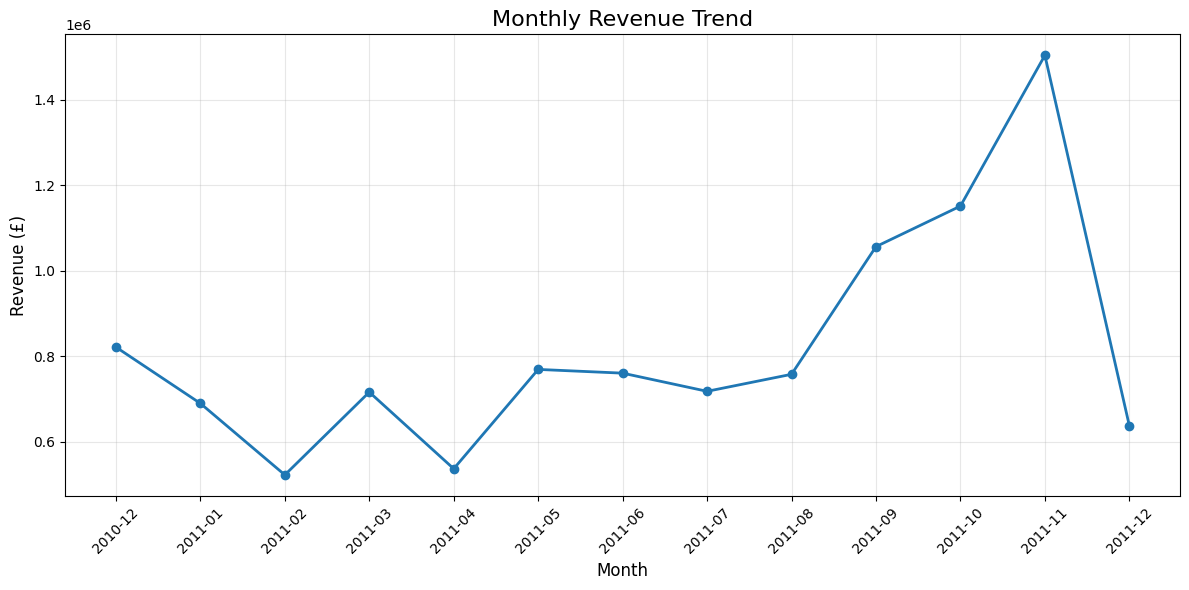

In [85]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_revenue["InvoiceDate"].astype(str),
    monthly_revenue["Revenue"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Revenue Trend", fontsize=16)
plt.xlabel("Month", fontsize=12)
plt.ylabel("Revenue (£)", fontsize=12)

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Top 10 Products by Revenue

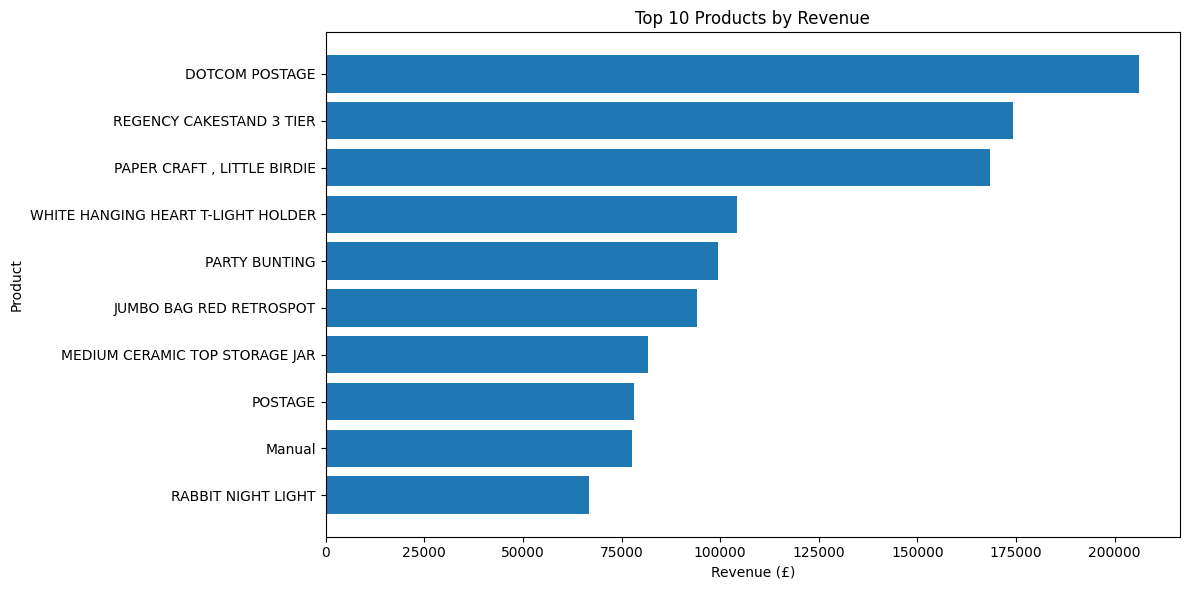

In [87]:
# Select the top 10 products by revenue
top_10_products = product_revenue.head(10)

# Create the figure and set its dimensions
plt.figure(figsize=(12, 6))

# Create a horizontal bar chart
plt.barh(
    top_10_products["Description"],
    top_10_products["Revenue"]
)

# Add chart title and axis labels
plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Product")

# Display the highest revenue product at the top
plt.gca().invert_yaxis()

# Adjust spacing and display the chart
plt.tight_layout()
plt.show()

# Top 10 International Markets

In [88]:
#removing UK as its already leading

international_revenue = country_revenue[
    country_revenue["Country"] != "United Kingdom"
]

top_10_countries = international_revenue.head(10)

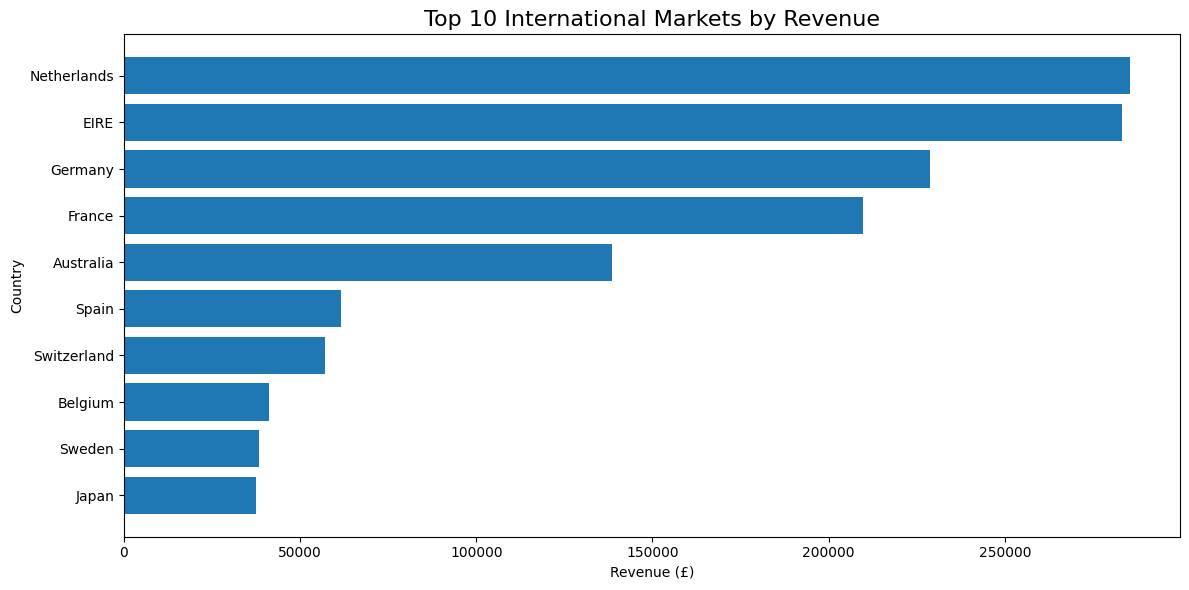

In [89]:
plt.figure(figsize=(12, 6))

plt.barh(
    top_10_countries["Country"],
    top_10_countries["Revenue"]
)

plt.title("Top 10 International Markets by Revenue", fontsize=16)
plt.xlabel("Revenue (£)")
plt.ylabel("Country")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

### International Market Analysis – Key Insights

- The Netherlands generated the highest revenue among international markets, followed closely by EIRE.
- Germany and France were also significant international revenue contributors.
- Although the business serves multiple international markets, revenue appears concentrated among a few leading countries.
- This indicates that international market presence does not necessarily translate into evenly distributed revenue.

**Business Recommendation:** The business could explore growth opportunities in lower-contributing international markets while strengthening relationships with its existing high-performing markets. This could help improve international revenue diversification and reduce dependence on a limited number of markets.

# 8. Business Insights and Recommendations

## Key Business Insights

**1. Overall Sales Performance**
- The analysis identified total gross revenue of £10,642,110.80 from 19,960 unique invoices.
- The average order value was approximately £533.17.

**2. Product Performance**
- Revenue was concentrated among a number of high-performing product entries.
- Grouping by both StockCode and Description provided a more detailed view of product-level revenue.
- Some product descriptions were associated with multiple stock codes.

**3. Geographical Performance**
- The United Kingdom contributed approximately 84.59% of total gross revenue.
- The Netherlands, EIRE, Germany and France were among the strongest international markets.
- International revenue was concentrated among a relatively small number of leading countries.

**4. Monthly Sales Performance**
- November 2011 recorded the highest monthly revenue at £1,503,866.78.
- Revenue increased significantly between September and November.
- December 2011 was an incomplete observation period, with transactions recorded only through December 9.

## Business Recommendations

1. **Strengthen International Markets:** Explore opportunities in lower-contributing international markets to diversify revenue.
2. **Optimize Inventory:** Use historical product performance to prioritize stock availability for high-revenue products.
3. **Prepare for Seasonal Demand:** Plan inventory, staffing and promotional campaigns ahead of historically strong sales periods.
4. **Monitor Revenue Concentration:** Track geographical revenue distribution to identify risks associated with dependence on a single market.

## Conclusion

This project demonstrated how Python and Pandas can be used to explore, clean and analyze retail transaction data. The analysis identified revenue patterns across products, countries and time periods, providing insights that can support inventory planning, sales strategies and geographical expansion.